# RQ3 Analysis: Type-Token Ratio (TTR)

Compares the lexical diversity (Type-Token Ratio) of human-written vs. LLM-generated PR descriptions.

- Uses `nltk.tokenize.word_tokenize` (academic standard) to tokenize text.
- TTR = number of unique tokens (types) / total number of tokens.
- Compares across models and prompt context variations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import word_tokenize
from scipy.stats import mannwhitneyu, kruskal
import paired_stats as PS  # Tier-A shared helpers: paired Wilcoxon, FDR, effect sizes
import scikit_posthocs as sp

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '/mnt/ext-hdd1/ayo/llm-in-prs/phase3/datasets/temperature_1/run_3_corrected_detection_v1/corpus.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct' 'gpt-5-mini-2025-08-07'
 'meta-llama/llama-3.1-70b-instruct']
Human entries: 308, AI entries: 5322


## 2. Compute Type-Token Ratio (TTR)

In [9]:
def compute_ttr(text):
    """Compute Type-Token Ratio for a given text using nltk word_tokenize."""
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    text = str(text)
    tokens = word_tokenize(text.lower())
    if len(tokens) == 0:
        return np.nan
    types = set(tokens)
    return len(types) / len(tokens)

In [10]:
# Apply to both subsets
human_df['ttr'] = human_df['text'].apply(compute_ttr)
ai_df['ttr'] = ai_df['text'].apply(compute_ttr)

In [11]:
# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['ttr'])

In [12]:
print("TTR metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'ttr']].head(10))

TTR metrics computed.
Combined dataset size: 5630


,entry_type,model,text,ttr
0,human,Human,Extracted Regexe in Patterns\r\nFix for #2451\...,0.611111
1,human,Human,Motivation is discussed in #2465. Fixes many c...,0.714286
2,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,0.821429
3,human,Human,Fixes https://github.com/JabRef/jabref/issues/...,0.582090
4,human,Human,"As discussed in #2704, unkown meta data items ...",0.602339
5,human,Human,"As suggested by @koppor in #2671, removes any ...",0.631068
6,human,Human,Followup from @sauliusg PR #2744\r\nFix for ...,0.909091
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,0.840909
8,human,Human,See #2762\r\nAdded a new LayoutFormatter that ...,0.698925
9,human,Human,\r\n![5digitgroups_fixed](https://cloud.github...,0.941176


## 3. Descriptive Statistics: Human vs AI (Overall)

In [13]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — Descriptive Statistics")
print(f"{'='*60}")


  Type-Token Ratio — Descriptive Statistics


In [14]:
stats = combined_df.groupby('source')['ttr'].describe()
stats['median'] = combined_df.groupby('source')['ttr'].median()
display(stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5322.0,0.693765,0.150375,0.277174,0.576389,0.677419,0.796875,1.0,0.677419
Human,308.0,0.625805,0.137970,0.398204,0.530379,0.595418,0.661007,1.0,0.595418


In [15]:
for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['ttr']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

  Human: Q1=0.5304, Median=0.5954, Q3=0.6610, IQR=0.1306
  AI: Q1=0.5764, Median=0.6774, Q3=0.7969, IQR=0.2205


## 4. Descriptive Statistics: By Model

In [16]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — By Model")
print(f"{'='*60}")


  Type-Token Ratio — By Model


In [17]:
stats_model = combined_df.groupby('model')['ttr'].describe()
stats_model['Median'] = combined_df.groupby('model')['ttr'].median()
stats_model['Q1'] = combined_df.groupby('model')['ttr'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['ttr'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

In [18]:
display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}))

,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308.0,0.625805,0.137970,0.595418,0.530379,0.661007,0.130627
Qwen/Qwen2.5-72B-Instruct,1772.0,0.698433,0.096199,0.693333,0.632447,0.765625,0.133178
gpt-5-mini-2025-08-07,1772.0,0.556826,0.082052,0.545862,0.500000,0.603669,0.103669
meta-llama/llama-3.1-70b-instruct,1778.0,0.825590,0.125175,0.833333,0.731434,0.928571,0.197137


## 5. Statistical Testing & Effect Size

In [19]:
def cliffs_delta(lst1, lst2):
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

In [20]:
def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

In [21]:
model_results = []

In [22]:
human_ttr = combined_df[combined_df['source'] == 'Human']['ttr'].values

In [23]:
# Per-model OVERALL comparison (PAIRED, per-PR mean across contexts) -- Tier-A.
# Replaces independent-samples Mann-Whitney U on paired human/AI data. For each model,
# summarise its six-context output per PR as the mean, then pair against the human value
# for the same PR (Wilcoxon signed-rank). Effect sizes: Cliff's delta (dominance) +
# matched-pairs rank-biserial. FDR (BH) applied within each metric. See paired_stats.py.
models = ai_df['model'].unique()
model_results = []
for _col, _label in [('ttr', 'Type-Token Ratio')]:
    _ai_all = ai_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _hu_all = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _m = pd.concat([_hu_all.rename('h'), _ai_all.rename('a')], axis=1, join='inner').dropna()
    _r = PS.paired_test(_m['h'].values, _m['a'].values)
    print("[%s] pooled Human vs AI (paired): n=%d, Wilcoxon p=%.3g, Cliff's d=%.4f (%s)"
          % (_label, _r['n'], _r['p'], _r['cliffs_delta'], _r['magnitude']))
    for _model in ai_df['model'].unique():
        _ai_pr = ai_df[ai_df['model'] == _model].dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _hu_pr = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _merged = pd.concat([_hu_pr.rename('h'), _ai_pr.rename('a')], axis=1, join='inner').dropna()
        _r = PS.paired_test(_merged['h'].values, _merged['a'].values)
        model_results.append({
            'Model': _model, 'Metric': _label, 'N pairs': _r['n'],
            'Human Median': _r['median_human'], 'Model Median': _r['median_ai'],
            'Wilcoxon p': _r['p'], "Cliff's Delta": round(_r['cliffs_delta'], 4),
            'Rank-Biserial': round(_r['rank_biserial'], 4), 'Effect Size': _r['magnitude'],
        })
model_results_df = pd.DataFrame(model_results)
model_results_df = PS.apply_fdr_by(model_results_df, 'Metric', pcol='Wilcoxon p')
model_results_df['Sig'] = model_results_df['adj_Wilcoxon p'].apply(PS.sig_mark)
display(model_results_df)


[Type-Token Ratio] pooled Human vs AI (paired): n=308, Wilcoxon p=1.47e-16, Cliff's d=-0.5545 (Large)


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,Qwen/Qwen2.5-72B-Instruct,Type-Token Ratio,308,0.595418,0.700862,2.232153e-17,-0.5644,-0.5576,Large,3.348229e-17,True,***
1,gpt-5-mini-2025-08-07,Type-Token Ratio,308,0.595418,0.558667,1.317087e-13,0.3097,0.4868,Small,1.317087e-13,True,***
2,meta-llama/llama-3.1-70b-instruct,Type-Token Ratio,308,0.595418,0.828050,2.753223e-46,-0.7607,-0.9391,Large,8.259670e-46,True,***


In [24]:
models = ai_df['model'].unique()

In [25]:
print(models)
display(model_results_df)  # Tier-A: reuse FDR-corrected per-model table built above


['Qwen/Qwen2.5-72B-Instruct' 'gpt-5-mini-2025-08-07'
 'meta-llama/llama-3.1-70b-instruct']


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,Qwen/Qwen2.5-72B-Instruct,Type-Token Ratio,308,0.595418,0.700862,2.232153e-17,-0.5644,-0.5576,Large,3.348229e-17,True,***
1,gpt-5-mini-2025-08-07,Type-Token Ratio,308,0.595418,0.558667,1.317087e-13,0.3097,0.4868,Small,1.317087e-13,True,***
2,meta-llama/llama-3.1-70b-instruct,Type-Token Ratio,308,0.595418,0.828050,2.753223e-46,-0.7607,-0.9391,Large,8.259670e-46,True,***


## 6. Visualizations

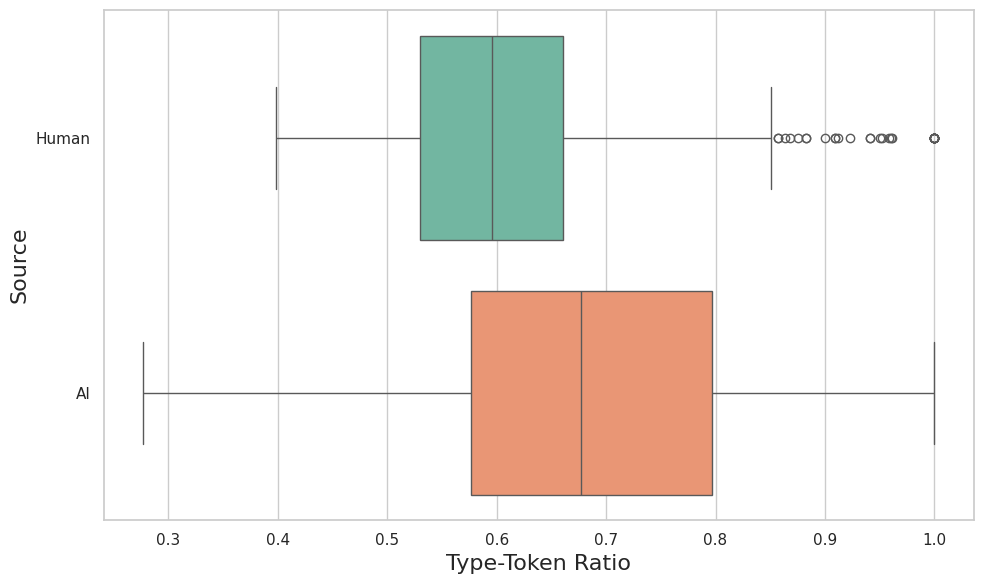

In [26]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='ttr', y='source', hue='source', palette='Set2', legend=False)
plt.xlabel("Type-Token Ratio", fontsize=16)
plt.ylabel("Source", fontsize=16)
plt.tight_layout()
plt.show()

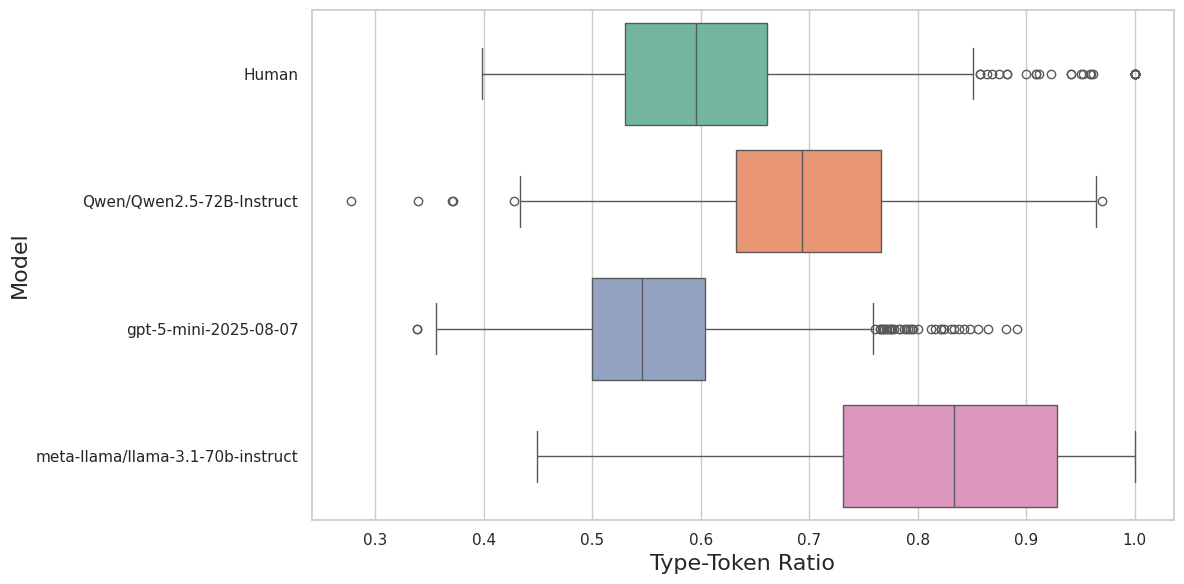

In [27]:
plt.figure(figsize=(12, 6))
order = ['Human'] + list(models)
sns.boxplot(data=combined_df, x='ttr', y='model', order=order, hue='model', palette='Set2', legend=False)
plt.xlabel("Type-Token Ratio", fontsize=16)
plt.ylabel("Model", fontsize=16)
plt.tight_layout()
plt.show()

## 7. TTR Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count, sentence-count, and FKGL setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline TTR boxplot is included in each panel for direct comparison.

In [28]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — By Prompt Context Variation")
print(f"{'='*60}")


  Type-Token Ratio — By Prompt Context Variation


In [29]:
# Filter to only AI data since 'human' entries don't have variation context
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['ttr'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['ttr'].median()
display(stats_ctx)

,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,912.0,0.651132,0.122781,0.277174,0.558298,0.638826,0.713054,1.0,0.638826
File Diff,924.0,0.693538,0.139318,0.338521,0.593360,0.683544,0.775598,1.0,0.683544
Linked Issue,819.0,0.670359,0.157698,0.338432,0.525620,0.676923,0.779536,1.0,0.676923
PR Title,924.0,0.770423,0.158797,0.375258,0.613013,0.811066,0.897436,1.0,0.811066
Repo Path,924.0,0.724144,0.154754,0.436195,0.603015,0.702254,0.820128,1.0,0.702254
Without File Contents,819.0,0.644142,0.123842,0.339623,0.547269,0.637584,0.724138,1.0,0.637584


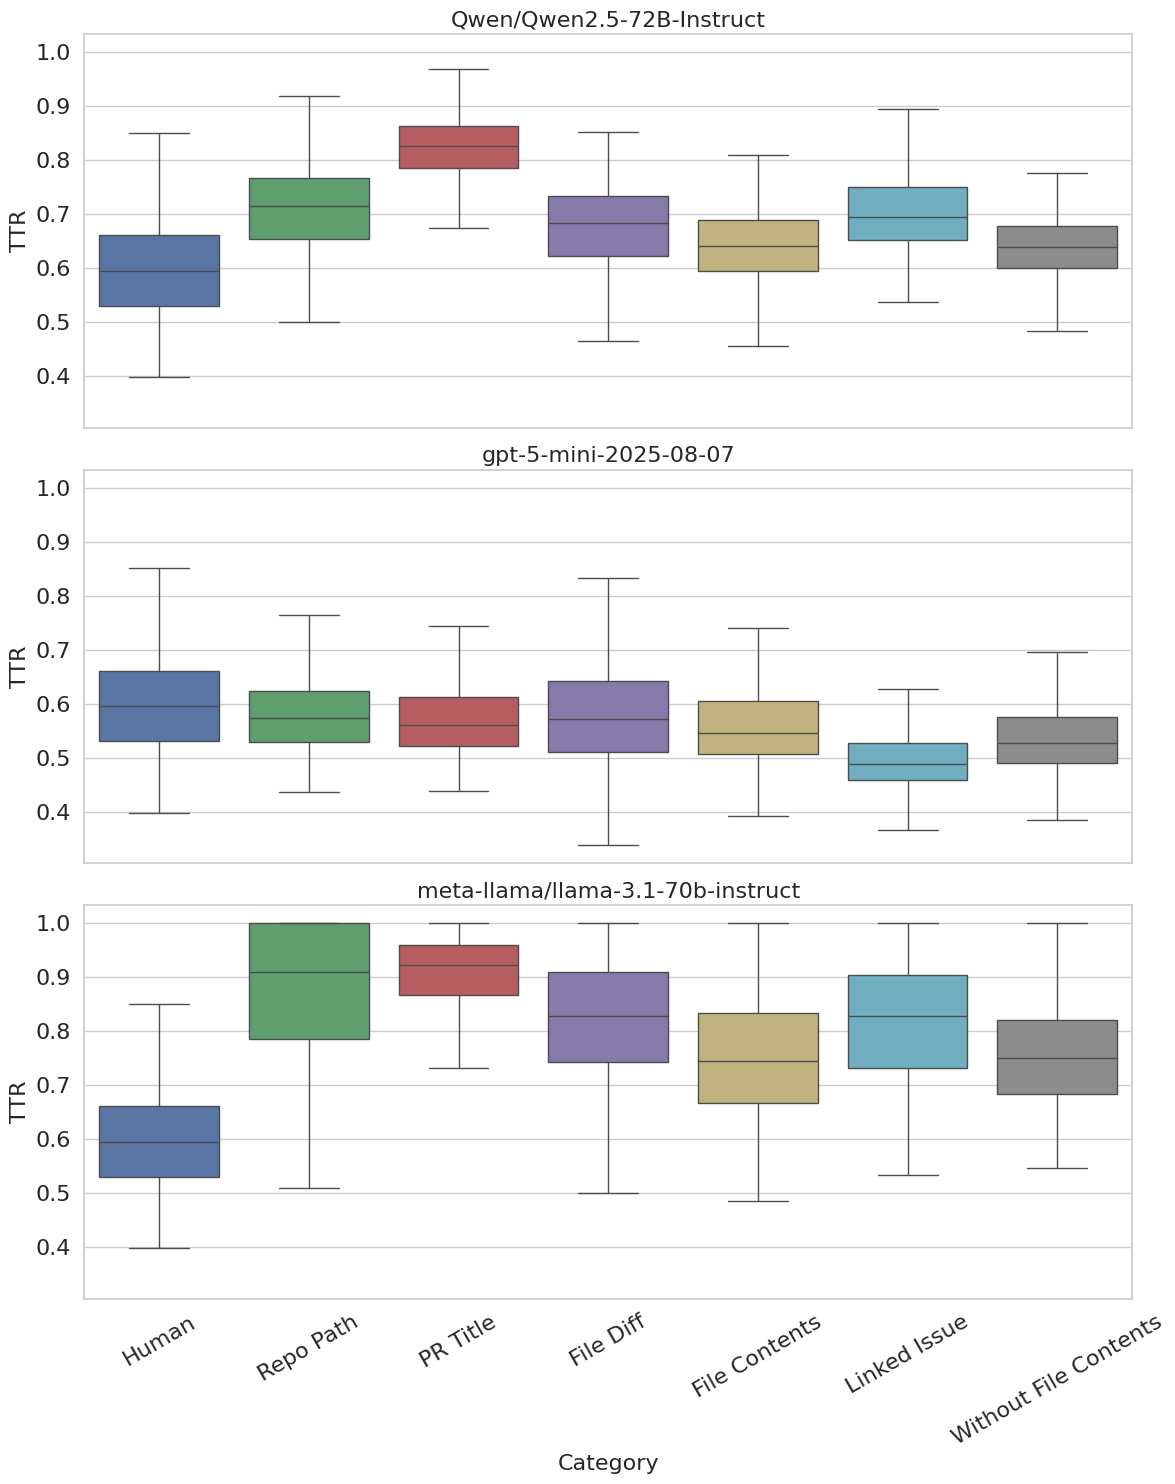

In [30]:
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    ai_slice = ai_df[ai_df['model'] == model][['ttr', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['ttr']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['ttr', 'Category']],
        ai_slice[['ttr', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='ttr',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('TTR', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'ttr.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for Type-Token Ratio.

In [31]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Type-Token Ratio)")
print(f"{'='*90}")


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Type-Token Ratio)


In [32]:
model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

In [33]:
# Human vs. AI per context (PAIRED): Cliff's delta + Wilcoxon signed-rank, BH-FDR -- Tier-A.
# Filter by the stable variation code (P-1..P-6); display labels differ across notebooks
# ('File Diff' vs 'PR Diffs', 'Linked Issue' vs 'Related Issues'), so the code is the safe key.
import os as _os
VARIATION_TO_CTX = {'P-1': 'Repo Path', 'P-2': 'PR Title', 'P-3': 'File Diff', 'P-4': 'File Contents', 'P-5': 'Linked Issue', 'P-6': 'Without File Contents'}
variation_codes = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
variation_names = [VARIATION_TO_CTX[_p] for _p in variation_codes]
_long = []
for _col, _label in [('ttr', 'Type-Token Ratio')]:
    for _model in ai_df['model'].unique():
        for _pcode in variation_codes:
            _slice = ai_df[(ai_df['model'] == _model) & (ai_df['variation'] == _pcode)]
            _r = PS.paired_test_from_frames(human_df, _slice, _col, key='normalized_pr_id')
            _long.append({'Metric': _label, 'Model': _model, 'Context': VARIATION_TO_CTX[_pcode],
                          'n': _r['n'], 'cliffs_delta': _r['cliffs_delta'], 'magnitude': _r['magnitude'],
                          'rank_biserial': _r['rank_biserial'], 'p': _r['p']})
long_df = PS.apply_fdr_by(pd.DataFrame(_long), 'Metric', pcol='p')
long_df['Sig'] = long_df['adj_p'].apply(PS.sig_mark)
_os.makedirs('outputs', exist_ok=True)
long_df.to_csv('outputs/rq2_ttr_paired_stats.csv', index=False)
print('Saved tidy paired stats -> outputs/rq2_ttr_paired_stats.csv')

def _fmt_cell(x):
    return "%.3f (%s) %s" % (x['cliffs_delta'], x['magnitude'][0], x['Sig'])
context_tables = {}
for _col, _label in [('ttr', 'Type-Token Ratio')]:
    _sub = long_df[long_df['Metric'] == _label].copy()
    _sub['cell'] = _sub.apply(_fmt_cell, axis=1)
    _piv = _sub.pivot(index='Model', columns='Context', values='cell').reindex(columns=variation_names)
    context_tables[_label] = _piv
    print("\n=== %s: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===" % _label)
    display(_piv)
result_df = list(context_tables.values())[-1]
effect_df = list(context_tables.values())[-1]


Saved tidy paired stats -> outputs/rq2_ttr_paired_stats.csv

=== Type-Token Ratio: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.518 (L) ***,-0.759 (L) ***,-0.395 (M) ***,-0.265 (S) ***,-0.521 (L) ***,-0.266 (S) **
gpt-5-mini-2025-08-07,0.127 (N) ***,0.199 (S) ***,0.152 (S) ***,0.272 (S) ***,0.644 (L) ***,0.401 (M) ***
meta-llama/llama-3.1-70b-instruct,-0.786 (L) ***,-0.864 (L) ***,-0.722 (L) ***,-0.575 (L) ***,-0.723 (L) ***,-0.635 (L) ***


In [34]:
display(result_df)  # Tier-A: reuse paired per-context table built above


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.518 (L) ***,-0.759 (L) ***,-0.395 (M) ***,-0.265 (S) ***,-0.521 (L) ***,-0.266 (S) **
gpt-5-mini-2025-08-07,0.127 (N) ***,0.199 (S) ***,0.152 (S) ***,0.272 (S) ***,0.644 (L) ***,0.401 (M) ***
meta-llama/llama-3.1-70b-instruct,-0.786 (L) ***,-0.864 (L) ***,-0.722 (L) ***,-0.575 (L) ***,-0.723 (L) ***,-0.635 (L) ***


## 9. Summary Table

In [35]:
summary_rows = []

In [36]:
for model in combined_df['model'].unique():
    vals = combined_df[combined_df['model'] == model]['ttr']
    summary_rows.append({
        'Model': model,
        'Metric': 'Type-Token Ratio',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

In [37]:
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Type-Token Ratio,308,0.6258,0.5954,0.1380,0.3982,1.0000,0.5304,0.6610
1,Qwen/Qwen2.5-72B-Instruct,Type-Token Ratio,1772,0.6984,0.6933,0.0962,0.2772,0.9697,0.6324,0.7656
2,gpt-5-mini-2025-08-07,Type-Token Ratio,1772,0.5568,0.5459,0.0821,0.3384,0.8913,0.5000,0.6037
3,meta-llama/llama-3.1-70b-instruct,Type-Token Ratio,1778,0.8256,0.8333,0.1252,0.4488,1.0000,0.7314,0.9286


In [38]:
import os
os.makedirs('outputs', exist_ok=True)

In [39]:
# Save summary to CSV
summary_df.to_csv('outputs/rq3_ttr_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_ttr_summary.csv")


Summary saved to outputs/rq3_ttr_summary.csv


In [40]:
from pathlib import Path as _ExportPath
_export_dir = _ExportPath('outputs/row_level')
_export_dir.mkdir(parents=True, exist_ok=True)
_export = pd.concat([human_df, ai_df], ignore_index=True)[
    ['normalized_pr_id', 'entry_type', 'model', 'variation', 'Context_Name', 'ttr']
].sort_values(['entry_type', 'model', 'variation', 'normalized_pr_id'], kind='stable')
_export.to_csv(_export_dir / 'ttr_metrics.csv', index=False)
print(f'Saved {len(_export)} row-level TTR records.')


Saved 5630 row-level TTR records.
